# Step 3 Model the accelerator

The arithmetic notebook showed **what answer a calculation produces**. This
notebook models **how many clock cycles a proposed machine needs to produce it**.

Choose **Runtime → Run all** in Colab. Explanations, code, diagrams, results, and
15 checks are included here. The first notebook, repository files, a dataset,
GPU, and Drive mount are not needed. Matplotlib draws the figures; it is included
in the standard Colab environment.

The final cell should finish with **OK** and **All 15 accelerator checks passed.**
The examples are small matrix calculations. The real digit-recognition workload
comes in the next step.


## 1 The machine we are proposing

The model contains **external memory**, a **local buffer**, and arithmetic units
called **lanes**. A buffer stores values near the arithmetic units. Bandwidth is
the number of bytes a connection can supply in one cycle. A cycle is one clock tick.

Each lane multiplies two values and adds the product to its own running total.
That multiply-and-add is one **MAC**. A lane works on one output at a time.

The following cell embeds the numerical helpers and configuration classes. It
uses the same arithmetic and simulator definitions as our local prototype.


In [1]:
from dataclasses import asdict, dataclass, replace
import math
import random
import struct
import sys
import unittest
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

INT8_MIN, INT8_MAX = -128, 127
INT32_MIN, INT32_MAX = -(2**31), 2**31 - 1

def fp32(value):
    """Round to IEEE binary32 using Python's standard library."""
    return struct.unpack("f", struct.pack("f", value))[0]


def fp32_mac(accumulator, left, right):
    """Separate rounded FP32 multiply and add; fused multiply-add is not modeled."""
    return fp32(accumulator + fp32(left * right))


def matrix_shape(matrix):
    """Reject empty or ragged matrices rather than silently truncating data."""
    if not matrix or not matrix[0]:
        raise ValueError("A matrix must have at least one row and column.")
    columns = len(matrix[0])
    if any(len(row) != columns for row in matrix):
        raise ValueError("All matrix rows must have the same length.")
    return len(matrix), columns


def multiplication_shape(left, right):
    rows, inner = matrix_shape(left)
    right_rows, columns = matrix_shape(right)
    if inner != right_rows:
        raise ValueError("Left columns must equal right rows.")
    return rows, inner, columns


def validate_int8(value):
    if type(value) is not int:
        raise TypeError("INT8 operands must be integers, not floats or booleans.")
    if not INT8_MIN <= value <= INT8_MAX:
        raise ValueError(f"Operand {value} is outside the signed INT8 range.")


def checked_mac(accumulator, left, right):
    """One multiply-and-add; flag overflow rather than use Python's wider integers."""
    validate_int8(left)
    validate_int8(right)
    if type(accumulator) is not int:
        raise TypeError("The accumulator must be an integer.")
    if not INT32_MIN <= accumulator <= INT32_MAX:
        raise OverflowError("Initial accumulator is outside the INT32 range.")
    result = accumulator + left * right
    if not INT32_MIN <= result <= INT32_MAX:
        raise OverflowError("INT32 accumulation overflow.")
    return result


@dataclass(frozen=True)
class AcceleratorConfig:
    lanes: int = 4
    scratchpad_bytes: int = 4096
    local_read_bytes_per_cycle: int = 8
    external_bytes_per_cycle: int = 4

    def __post_init__(self):
        for name, value in asdict(self).items():
            if type(value) is not int or value <= 0:
                raise ValueError(f"{name} must be a positive integer.")
        if self.local_read_bytes_per_cycle < 2:
            raise ValueError("The local read bus must support at least one INT8 operand pair.")


@dataclass
class SimulationResult:
    output: list[list[int | float]]
    config: AcceleratorConfig
    metrics: dict
    trace: list[dict]

print("Arithmetic helpers and hardware settings are ready.")


Arithmetic helpers and hardware settings are ready.


## 2 Choose hardware assumptions

These values describe our hypothetical machine. The professor allows justified
choices; they are not specifications supplied by her.

| Choice | Starting value | Reason |
|---|---:|---|
| Lanes | 8; also compare 1 and 4 | Show whether parallel arithmetic helps |
| Local buffer | 256 KiB | Fits the planned largest FP32 matrix stage, 204,096 bytes |
| Shared local reads | 32 bytes/cycle | Makes operand size and read bandwidth visible |
| External transfers | 32 bytes/cycle | Keep the loading/storing budget fixed in comparisons |
| Assumed clock | 100 MHz | A round reference for converting cycles into time |
| Arithmetic capacity | 1 MAC/lane/cycle | A simple starting rule for both precisions |

A KiB is 1,024 bytes. Our planned 784-input, 64-output layer needs
`4 × (784 + 784 × 64 + 64) = 204,096` bytes for FP32 input, weights, and output.
It fits in 262,144 bytes. This is active matrix storage, separate from the
space occupied by the complete saved model.

The model does not establish an achievable physical clock or equal chip area
for FP32 and INT8. Those would require more detailed hardware work.


In [2]:
CLOCK_HZ = 100_000_000
BASE_CONFIG = AcceleratorConfig(
    lanes=8,
    scratchpad_bytes=256 * 1024,
    local_read_bytes_per_cycle=32,
    external_bytes_per_cycle=32,
)
print("Starting hardware settings:")
for name, value in asdict(BASE_CONFIG).items():
    print(f"  {name}: {value:,}")
print(f"Assumed clock: {CLOCK_HZ / 1_000_000:g} MHz")
print(f"One cycle: {1_000_000_000 / CLOCK_HZ:g} nanoseconds")
print(f"Assumed peak rate of each 32-byte/cycle bus: {32 * CLOCK_HZ / 1e9:g} GB/s")
print("Planned largest FP32 matrix stage:", 4 * (784 + 784 * 64 + 64), "bytes")


Starting hardware settings:
  lanes: 8
  scratchpad_bytes: 262,144
  local_read_bytes_per_cycle: 32
  external_bytes_per_cycle: 32
Assumed clock: 100 MHz
One cycle: 10 nanoseconds
Assumed peak rate of each 32-byte/cycle bus: 3.2 GB/s
Planned largest FP32 matrix stage: 204096 bytes


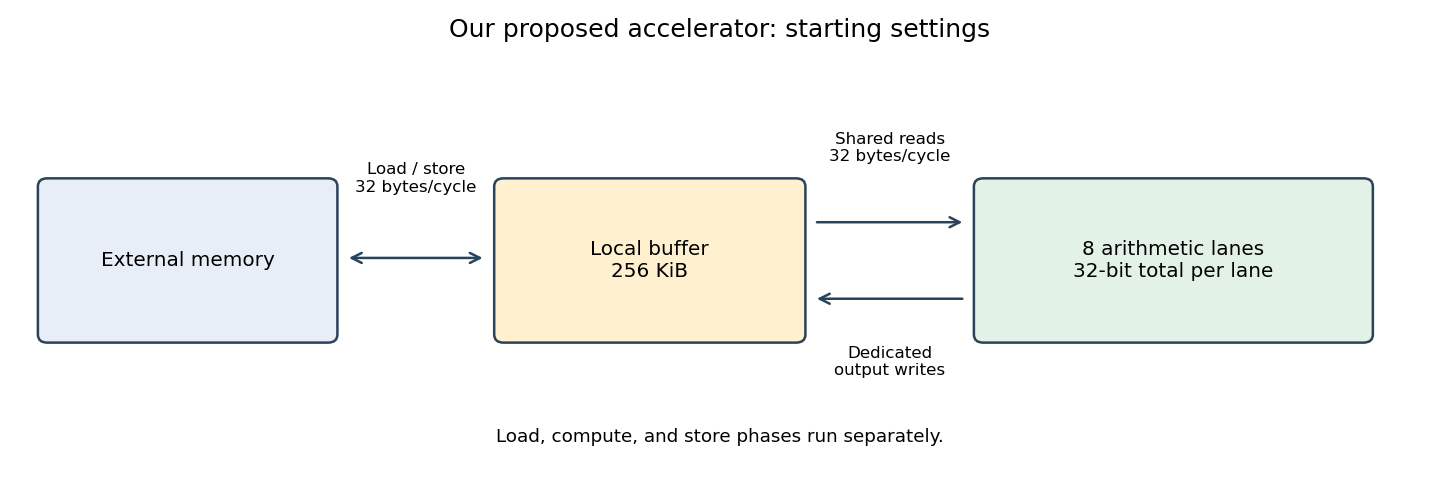

In [3]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.set(xlim=(0, 12), ylim=(0, 4))
ax.axis("off")
boxes = [
    (0.25, 1.25, 2.4, 1.45, "External memory", "#e8eef8"),
    (4.15, 1.25, 2.5, 1.45, "Local buffer\n256 KiB", "#fff0cf"),
    (8.25, 1.25, 3.25, 1.45, "8 arithmetic lanes\n32-bit total per lane", "#e3f2e6"),
]
for x, y, width, height, label, color in boxes:
    ax.add_patch(FancyBboxPatch((x, y), width, height,
                               boxstyle="round,pad=0.08", facecolor=color,
                               edgecolor="#29435b", linewidth=1.5))
    ax.text(x + width / 2, y + height / 2, label, ha="center", va="center", fontsize=12)
ax.add_patch(FancyArrowPatch((2.8, 2), (4, 2), arrowstyle="<->", mutation_scale=15,
                            linewidth=1.5, color="#29435b"))
ax.text(3.4, 2.65, "Load / store\n32 bytes/cycle", ha="center", fontsize=10)
ax.add_patch(FancyArrowPatch((6.8, 2.35), (8.1, 2.35), arrowstyle="->", mutation_scale=15,
                            linewidth=1.5, color="#29435b"))
ax.text(7.45, 2.95, "Shared reads\n32 bytes/cycle", ha="center", fontsize=10)
ax.add_patch(FancyArrowPatch((8.1, 1.6), (6.8, 1.6), arrowstyle="->", mutation_scale=15,
                            linewidth=1.5, color="#29435b"))
ax.text(7.45, 0.85, "Dedicated\noutput writes", ha="center", fontsize=10)
ax.set_title("Our proposed accelerator: starting settings", fontsize=15, pad=10)
ax.text(6, 0.2, "Load, compute, and store phases run separately.", ha="center", fontsize=11)
fig.tight_layout()
plt.show()


## 3 How execution is counted

Each matrix operation has four phases:

1. Load inputs into the local buffer.
2. Load weights into the local buffer.
3. Read operand pairs and calculate output values.
4. Store the 32-bit results back to external memory.

The phases do not overlap. Each transfer needs `ceil(bytes / external bandwidth)`
cycles, including a partly used final cycle. A lane can issue at most one MAC in
a cycle. The shared local read budget may allow fewer lanes to work.

Outputs are assigned to lanes in groups. A group finishes before the next one
starts. Each lane calculates a complete dot product in order. If there is not
enough read bandwidth, a round-robin rule gives lanes turns. The model reads both
operands for every MAC; it does not broadcast or reuse an operand across MACs.
Final accumulator values write to the local buffer through dedicated output
ports in the final MAC cycle, with no added write delay or bank conflicts.

The next cell embeds the simulator. It executes the arithmetic while counting
cycles; it does not simply divide the operation count by the number of lanes.


In [4]:
def simulate_matmul(left, right, config=None, *, record_trace=True, precision="int8"):
    config = config or AcceleratorConfig()
    rows, inner, columns = multiplication_shape(left, right)
    if precision not in ("int8", "fp32"):
        raise ValueError("Supported precisions are int8 and fp32.")
    operand_bytes = 1 if precision == "int8" else 4
    pair_bytes = 2 * operand_bytes
    if config.local_read_bytes_per_cycle < pair_bytes:
        raise ValueError(f"{precision} requires {pair_bytes} local read bytes per MAC.")
    for matrix in (left, right):
        for row in matrix:
            for value in row:
                if precision == "int8":
                    validate_int8(value)
                elif not math.isfinite(float(value)):
                    raise ValueError("FP32 operands must be finite.")
    if precision == "fp32":
        left = [[fp32(value) for value in row] for row in left]
        right = [[fp32(value) for value in row] for row in right]

    input_bytes = rows * inner * operand_bytes
    weight_bytes = inner * columns * operand_bytes
    output_bytes = rows * columns * 4  # INT32 or FP32 outputs, no INT8 requantization.
    required = input_bytes + weight_bytes + output_bytes
    if required > config.scratchpad_bytes:
        raise ValueError(
            f"Resident matrices need {required} scratchpad bytes; "
            f"only {config.scratchpad_bytes} provided. Tiling is not implemented yet."
        )

    output = [[0 if precision == "int8" else 0.0] * columns for _ in range(rows)]
    trace = []
    cycle = 0
    phase_cycles = {}

    def transfer(phase, byte_count):
        nonlocal cycle
        start = cycle
        remaining = byte_count
        while remaining:
            moved = min(remaining, config.external_bytes_per_cycle)
            cycle += 1
            if record_trace:
                trace.append({"cycle": cycle, "phase": phase, "bytes": moved})
            remaining -= moved
        phase_cycles[phase] = cycle - start

    transfer("load_inputs", input_bytes)
    transfer("load_weights", weight_bytes)
    compute_start = cycle
    blocked_lane_cycles = 0
    mac_count = 0
    outputs = [(row, column) for row in range(rows) for column in range(columns)]
    macs_per_cycle = min(config.lanes, config.local_read_bytes_per_cycle // pair_bytes)
    mac = checked_mac if precision == "int8" else fp32_mac

    for group_start in range(0, len(outputs), config.lanes):
        jobs = outputs[group_start:group_start + config.lanes]
        progress = [0] * len(jobs)
        cursor = 0
        while any(k < inner for k in progress):
            cycle += 1
            ready = []
            for offset in range(len(jobs)):
                lane = (cursor + offset) % len(jobs)
                if progress[lane] < inner:
                    ready.append(lane)
            issued = ready[:macs_per_cycle]
            blocked_lane_cycles += len(ready) - len(issued)
            operations = []
            for lane in issued:
                row, column = jobs[lane]
                k = progress[lane]
                a, b = left[row][k], right[k][column]
                output[row][column] = mac(output[row][column], a, b)
                progress[lane] += 1
                mac_count += 1
                if record_trace:
                    operations.append({
                        "lane": lane, "output": [row, column], "k": k,
                        "left": a, "right": b, "product": a * b,
                        "accumulator": output[row][column],
                        "finished": progress[lane] == inner,
                    })
            cursor = (issued[-1] + 1) % len(jobs)
            if record_trace:
                trace.append({"cycle": cycle, "phase": "compute", "macs": operations})

    phase_cycles["compute"] = cycle - compute_start
    transfer("store_outputs", output_bytes)
    compute_cycles = phase_cycles["compute"]
    metrics = {
        "precision": precision,
        "rows": rows, "inner": inner, "columns": columns,
        "macs": mac_count, "total_cycles": cycle,
        **{f"{phase}_cycles": count for phase, count in phase_cycles.items()},
        "input_bytes": input_bytes, "weight_bytes": weight_bytes,
        "output_bytes": output_bytes, "scratchpad_required_bytes": required,
        "external_bytes_transferred": input_bytes + weight_bytes + output_bytes,
        "local_operand_bytes_read": pair_bytes * mac_count,
        "bandwidth_blocked_lane_cycles": blocked_lane_cycles,
        "compute_lane_utilization": mac_count / (compute_cycles * config.lanes),
        "macs_per_total_cycle": mac_count / cycle,
    }
    return SimulationResult(output, config, metrics, trace)

print("Simulator ready: load inputs → load weights → compute → store outputs.")


Simulator ready: load inputs → load weights → compute → store outputs.


## 4 Follow the familiar answer 29 through the machine

Use **one lane** initially so its activity is easy to follow. The other starting
settings stay the same.

`2 × 4 + 3 × 5 + 1 × 6 = 29`

| Phase | Data or work | Expected cycles |
|---|---|---:|
| Load inputs | 3 INT8 bytes; fits one transfer | 1 |
| Load weights | 3 INT8 bytes; fits one transfer | 1 |
| Compute | 3 dependent MACs on one lane | 3 |
| Store output | 1 INT32 value, or 4 bytes | 1 |
| **Total** | | **6** |

A single lane processes this running total in order. In this design, adding lanes
helps when there are more output values to calculate; it does not split one dot
product across several lanes.


In [5]:
small_left = [[2, 3, 1]]
small_right = [[4], [5], [6]]
small = simulate_matmul(small_left, small_right, replace(BASE_CONFIG, lanes=1))
phase_names = {"load_inputs": "load inputs", "load_weights": "load weights",
               "store_outputs": "store the INT32 result"}
for event in small.trace:
    if event["phase"] == "compute":
        operation = event["macs"][0]
        detail = (f"{operation['left']} * {operation['right']} = {operation['product']}; "
                  f"running total {operation['accumulator']}")
    else:
        detail = f"{phase_names[event['phase']]} ({event['bytes']} bytes)"
    print(f"Cycle {event['cycle']}: {detail}")
print("Answer:", small.output[0][0])
print("Total cycles:", small.metrics["total_cycles"])


Cycle 1: load inputs (3 bytes)
Cycle 2: load weights (3 bytes)
Cycle 3: 2 * 4 = 8; running total 8
Cycle 4: 3 * 5 = 15; running total 23
Cycle 5: 1 * 6 = 6; running total 29
Cycle 6: store the INT32 result (4 bytes)
Answer: 29
Total cycles: 6


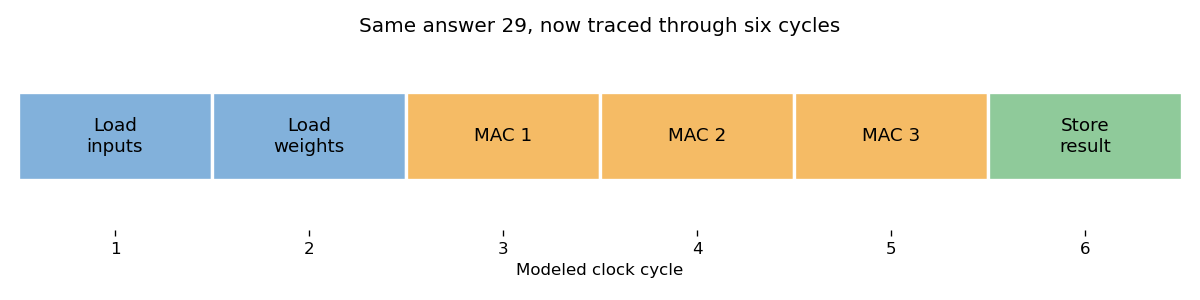

In [6]:
colors = {"load_inputs": "#82b1db", "load_weights": "#82b1db",
          "compute": "#f5bb65", "store_outputs": "#8fca9a"}
labels = {"load_inputs": "Load\ninputs", "load_weights": "Load\nweights",
          "store_outputs": "Store\nresult"}
fig, ax = plt.subplots(figsize=(10, 2.5))
for event in small.trace:
    cycle = event["cycle"]
    ax.barh(0, 1, left=cycle - 1, height=0.75,
            color=colors[event["phase"]], edgecolor="white", linewidth=2)
    text = labels.get(event["phase"], "MAC " + str(cycle - 2))
    ax.text(cycle - 0.5, 0, text, ha="center", va="center", fontsize=11)
ax.set(xlim=(0, 6), ylim=(-0.8, 0.8), yticks=[],
       xticks=[i + 0.5 for i in range(6)], xticklabels=range(1, 7),
       xlabel="Modeled clock cycle", title="Same answer 29, now traced through six cycles")
for spine in ax.spines.values():
    spine.set_visible(False)
fig.tight_layout()
plt.show()


## 5 Convert cycles into estimated time

At an assumed **100 MHz**, the clock has 100,000,000 cycles per second.
One cycle lasts 10 nanoseconds, so the six-cycle example takes **60 nanoseconds**
in this model.

`estimated time = cycles / assumed clock frequency`

This is not a measurement of how quickly Python runs. Changing the assumed clock
changes the estimated time but does not change the cycle schedule.


In [7]:
def timing_metrics(cycles, macs, clock_hz):
    for name, value in (("cycles", cycles), ("macs", macs), ("clock_hz", clock_hz)):
        if type(value) is not int or value <= 0:
            raise ValueError(f"{name} must be a positive integer.")
    seconds = cycles / clock_hz
    return {
        "clock_hz": clock_hz,
        "matrix_latency_seconds": seconds,
        "matrix_latency_microseconds": seconds * 1_000_000,
        "macs_per_cycle": macs / cycles,
        "macs_per_second": macs / seconds,
    }

small_timing = timing_metrics(small.metrics["total_cycles"], small.metrics["macs"], CLOCK_HZ)
print(f"{small.metrics['total_cycles']} cycles at {CLOCK_HZ / 1e6:g} MHz")
print(f"Estimated matrix time: {small_timing['matrix_latency_seconds'] * 1e9:.0f} nanoseconds")
print(f"Same cycles at 200 MHz: {timing_metrics(6, 3, 200_000_000)['matrix_latency_seconds'] * 1e9:.0f} nanoseconds")


6 cycles at 100 MHz
Estimated matrix time: 60 nanoseconds
Same cycles at 200 MHz: 30 nanoseconds


## 6 Give multiple lanes enough work

Now use the same three inputs to calculate **eight output values**. This needs
`3 × 8 = 24` MACs. Every output is 29, so all configurations can be checked easily.

Keep both bandwidths at 32 bytes/cycle. INT8 input, weights, and outputs take
1 + 1 + 1 = **3 transfer cycles**. At 1, 4, and 8 lanes, the compute work needs
24, 6, and 3 cycles, respectively. Expected totals are **27, 9, and 6**.

The result stays the same; the resource count changes how long it takes.


In [8]:
experiment_left = [[2, 3, 1]]
experiment_right = [[4] * 8, [5] * 8, [6] * 8]
lane_results = []
print("Lanes | Compute cycles | Transfer cycles | Total cycles | Answer check")
for lanes in (1, 4, 8):
    simulation = simulate_matmul(experiment_left, experiment_right,
                                  replace(BASE_CONFIG, lanes=lanes), record_trace=False)
    metrics = simulation.metrics
    lane_results.append((lanes, metrics))
    transfer = metrics["total_cycles"] - metrics["compute_cycles"]
    print(f"{lanes:5d} | {metrics['compute_cycles']:14d} | {transfer:15d} | "
          f"{metrics['total_cycles']:12d} | {simulation.output == [[29] * 8]}")


Lanes | Compute cycles | Transfer cycles | Total cycles | Answer check
    1 |             24 |               3 |           27 | True
    4 |              6 |               3 |            9 | True
    8 |              3 |               3 |            6 | True


## 7 Memory can keep arithmetic units waiting

Each INT8 MAC reads two one-byte operands. With eight lanes:

- A **2-byte/cycle** read bus feeds only one lane per cycle.
- An **8-byte/cycle** read bus feeds at most four lanes per cycle.
- A **32-byte/cycle** read bus can supply all eight lanes.

Keep external transfers at 32 bytes/cycle. Expected total cycle counts are
**27, 9, and 6**. Eight lanes with a narrow read bus can be no faster than one
lane with enough bandwidth. This is the same resource-and-waiting-time reasoning
used in processor and memory analysis.


In [9]:
bandwidth_results = []
print("Local read bytes/cycle | Compute cycles | Transfer cycles | Total cycles")
for bandwidth in (2, 8, 32):
    simulation = simulate_matmul(experiment_left, experiment_right,
                                  replace(BASE_CONFIG, local_read_bytes_per_cycle=bandwidth),
                                  record_trace=False)
    metrics = simulation.metrics
    bandwidth_results.append((bandwidth, metrics))
    transfer = metrics["total_cycles"] - metrics["compute_cycles"]
    print(f"{bandwidth:22d} | {metrics['compute_cycles']:14d} | {transfer:15d} | {metrics['total_cycles']:12d}")


Local read bytes/cycle | Compute cycles | Transfer cycles | Total cycles
                     2 |             24 |               3 |           27
                     8 |              6 |               3 |            9
                    32 |              3 |               3 |            6


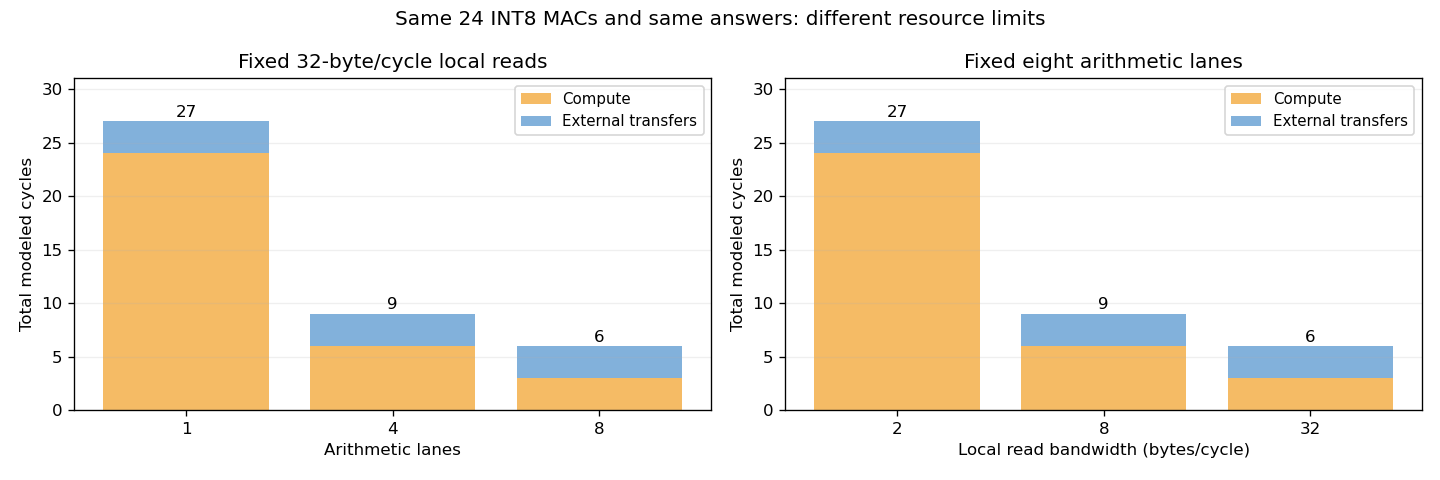

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, rows, xlabel, title in [
    (axes[0], lane_results, "Arithmetic lanes", "Fixed 32-byte/cycle local reads"),
    (axes[1], bandwidth_results, "Local read bandwidth (bytes/cycle)", "Fixed eight arithmetic lanes"),
]:
    positions = list(range(len(rows)))
    compute = [metrics["compute_cycles"] for _, metrics in rows]
    transfer = [metrics["total_cycles"] - metrics["compute_cycles"] for _, metrics in rows]
    ax.bar(positions, compute, color="#f5bb65", label="Compute")
    ax.bar(positions, transfer, bottom=compute, color="#82b1db", label="External transfers")
    for position, (_, metrics) in zip(positions, rows):
        ax.text(position, metrics["total_cycles"] + 0.4, str(metrics["total_cycles"]), ha="center")
    ax.set(xticks=positions, xticklabels=[str(value) for value, _ in rows],
           xlabel=xlabel, ylabel="Total modeled cycles", ylim=(0, 31), title=title)
    ax.legend(loc="upper right", fontsize=9)
    ax.grid(axis="y", alpha=0.2)
fig.suptitle("Same 24 INT8 MACs and same answers: different resource limits", fontsize=12)
fig.tight_layout()
plt.show()


## 8 Compare INT8 and FP32 under matching assumptions

INT8 reads **2 bytes per MAC**; FP32 reads **8 bytes per MAC**. A 32-byte read
budget therefore feeds up to sixteen INT8 MACs or four FP32 MACs per cycle.
With only eight lanes available, those limits become eight and four.

Both formats store each output in **four bytes**: INT32 totals for INT8, FP32
totals for FP32. Smaller inputs therefore do not make every byte count four
times smaller.

The small values below are exactly representable in both formats. This example
isolates storage and scheduling effects; it does not measure quantization error
or network accuracy. The one-MAC/lane/cycle rule and clock are the same for both
formats. Equal lane counts do not establish equal chip area or power.


In [11]:
precision_results = {}
print("Lanes | FP32 cycles | INT8 cycles | FP32 cycles / INT8 cycles")
for lanes in (1, 4, 8):
    pair = {}
    for precision in ("fp32", "int8"):
        simulation = simulate_matmul(experiment_left, experiment_right,
                                      replace(BASE_CONFIG, lanes=lanes),
                                      precision=precision, record_trace=False)
        pair[precision] = simulation.metrics
        if simulation.output != [[29] * 8]:
            raise AssertionError("A precision comparison changed the numerical answer.")
    precision_results[lanes] = pair
    print(f"{lanes:5d} | {pair['fp32']['total_cycles']:11d} | {pair['int8']['total_cycles']:11d} | "
          f"{pair['fp32']['total_cycles'] / pair['int8']['total_cycles']:.3f}")
print("\nEight lanes: storage, traffic, and estimated performance")
for precision, metrics in precision_results[8].items():
    timing = timing_metrics(metrics["total_cycles"], metrics["macs"], CLOCK_HZ)
    print(f"{precision.upper()}: local bytes {metrics['scratchpad_required_bytes']}, "
          f"external bytes {metrics['external_bytes_transferred']}, "
          f"output bytes {metrics['output_bytes']}, "
          f"time {timing['matrix_latency_microseconds']:.3f} microseconds, "
          f"throughput {timing['macs_per_second'] / 1e6:.2f} million MAC/s")


Lanes | FP32 cycles | INT8 cycles | FP32 cycles / INT8 cycles
    1 |          29 |          27 | 1.074
    4 |          11 |           9 | 1.222
    8 |          11 |           6 | 1.833

Eight lanes: storage, traffic, and estimated performance
FP32: local bytes 140, external bytes 140, output bytes 32, time 0.110 microseconds, throughput 218.18 million MAC/s
INT8: local bytes 59, external bytes 59, output bytes 32, time 0.060 microseconds, throughput 400.00 million MAC/s


At eight lanes the expected totals are **11 cycles for FP32** and **6 for INT8**,
about **1.83×** speedup for this small case. FP32 does not improve between four
and eight lanes because its local read bus supplies only four MACs per cycle.

This is a finding about the specified toy matrices and model. It is not a
speedup claim for complete digit recognition or for Python running on a CPU.


## 9 Capacity is different from bandwidth

Bandwidth limits how quickly data moves. Capacity limits how much fits at once.
This INT8 example needs **3 input bytes + 24 weight bytes + 32 output bytes = 59**.

A 58-byte buffer cannot run it under our resident-matrix design. The model rejects
that case. It does not silently increase the memory or add unimplemented tiling.
The error is caught below so Run all continues.


In [12]:
try:
    simulate_matmul(experiment_left, experiment_right,
                    replace(BASE_CONFIG, scratchpad_bytes=58), record_trace=False)
except ValueError as error:
    print("Expected capacity error:", error)
fits = simulate_matmul(experiment_left, experiment_right,
                       replace(BASE_CONFIG, scratchpad_bytes=59), record_trace=False)
print("With exactly 59 bytes, the answer is:", fits.output)


Expected capacity error: Resident matrices need 59 scratchpad bytes; only 58 provided. Tiling is not implemented yet.
With exactly 59 bytes, the answer is: [[29, 29, 29, 29, 29, 29, 29, 29]]


## 10 Try a different machine

These values can be edited before running this cell again. Earlier examples and
the tests use their own settings, so this experiment does not alter them.

Try reducing the local read bandwidth to 2 bytes/cycle or the buffer to 58 bytes.
Observe whether the calculation gets slower or cannot run at all.


In [13]:
try_lanes = 4
try_local_read_bytes = 8
try_external_bytes = 32
try_buffer_bytes = 256
try_clock_hz = 100_000_000

try:
    try_config = AcceleratorConfig(lanes=try_lanes, scratchpad_bytes=try_buffer_bytes,
                                   local_read_bytes_per_cycle=try_local_read_bytes,
                                   external_bytes_per_cycle=try_external_bytes)
    trial = simulate_matmul(experiment_left, experiment_right, try_config, record_trace=False)
    trial_time = timing_metrics(trial.metrics["total_cycles"], trial.metrics["macs"], try_clock_hz)
    print("Answer:", trial.output)
    print("Compute cycles:", trial.metrics["compute_cycles"])
    print("Total cycles:", trial.metrics["total_cycles"])
    print(f"Estimated time: {trial_time['matrix_latency_microseconds']:.3f} microseconds")
except ValueError as error:
    print("These settings cannot run this experiment:", error)


Answer: [[29, 29, 29, 29, 29, 29, 29, 29]]
Compute cycles: 6
Total cycles: 9
Estimated time: 0.090 microseconds


## 11 Check the model against known answers

The checks include independent hand-calculated schedules, fair sharing of read
bandwidth, partial transfers, numerical answers, capacity rejection, and the
clock-to-time conversion. Random small matrices also check every issued MAC
against the available lanes and bus budget.

There are nine checks from the simulator prototype and six additional checks for
this notebook's examples. Expected final result: **All 15 accelerator checks passed.**


In [14]:
class SimulatorTests(unittest.TestCase):
    def setUp(self):
        self.left = [[2, 3, 1], [-1, 0, 2]]
        self.right = [[4, -2], [5, 3], [6, 1]]

    def test_hand_derived_schedule_and_partial_transfers(self):
        result = simulate_matmul(self.left, self.right)
        self.assertEqual(result.output, [[29, 6], [8, 4]])
        # 6 input bytes: 2 cycles. 6 weight bytes: 2 cycles.
        # Four dot products of length three: 3 compute cycles.
        # Four INT32 outputs (16 bytes): 4 store cycles. Total: 11.
        expected_phases = (["load_inputs"] * 2 + ["load_weights"] * 2
                           + ["compute"] * 3 + ["store_outputs"] * 4)
        self.assertEqual([event["phase"] for event in result.trace], expected_phases)
        self.assertEqual([event["cycle"] for event in result.trace], list(range(1, 12)))
        self.assertEqual(result.metrics["total_cycles"], 11)
        self.assertEqual(result.metrics["scratchpad_required_bytes"], 28)
        self.assertEqual(result.metrics["local_operand_bytes_read"], 24)
        self.assertEqual(result.metrics["macs"], 12)
        self.assertEqual(result.trace[0]["bytes"], 4)
        self.assertEqual(result.trace[1]["bytes"], 2)
        operations = result.trace[4]["macs"]
        self.assertEqual([op["product"] for op in operations], [8, -4, -4, 2])
        self.assertEqual([op["k"] for op in operations], [0, 0, 0, 0])

    def test_bandwidth_prevents_speedup_and_arbiter_rotates(self):
        serial = simulate_matmul(self.left, self.right, AcceleratorConfig(
            lanes=1, local_read_bytes_per_cycle=2))
        parallel = simulate_matmul(self.left, self.right, AcceleratorConfig(
            lanes=4, local_read_bytes_per_cycle=2))
        self.assertEqual(serial.metrics["compute_cycles"], 12)
        self.assertEqual(parallel.metrics["compute_cycles"], 12)
        self.assertEqual(serial.metrics["total_cycles"], parallel.metrics["total_cycles"])
        issued_lanes = [event["macs"][0]["lane"] for event in parallel.trace
                        if event["phase"] == "compute"]
        self.assertEqual(issued_lanes, [0, 1, 2, 3] * 3)
        self.assertEqual(parallel.metrics["bandwidth_blocked_lane_cycles"], 30)

    def test_group_tail_cost(self):
        result = simulate_matmul([[1, 2]], [[1] * 5, [1] * 5])
        self.assertEqual(result.output, [[3] * 5])
        self.assertEqual(result.metrics["compute_cycles"], 4)
        self.assertEqual(result.metrics["compute_lane_utilization"], 10 / 16)

    def test_exact_capacity_and_reject_insufficient_buffer(self):
        simulate_matmul(self.left, self.right, AcceleratorConfig(scratchpad_bytes=28))
        with self.assertRaisesRegex(ValueError, "Tiling is not implemented"):
            simulate_matmul(self.left, self.right, AcceleratorConfig(scratchpad_bytes=27))

    def test_invalid_configurations(self):
        for setting in ({"lanes": 0}, {"lanes": 1.5}, {"lanes": True},
                        {"scratchpad_bytes": -1}, {"local_read_bytes_per_cycle": 1},
                        {"external_bytes_per_cycle": 0}):
            with self.subTest(setting=setting), self.assertRaises(ValueError):
                AcceleratorConfig(**setting)

    def test_trace_can_be_disabled_without_changing_results(self):
        traced = simulate_matmul(self.left, self.right)
        untraced = simulate_matmul(self.left, self.right, record_trace=False)
        self.assertEqual(untraced.trace, [])
        self.assertEqual(traced.output, untraced.output)
        self.assertEqual(traced.metrics, untraced.metrics)

    def test_fp32_bytes_schedule_and_result(self):
        config = AcceleratorConfig(local_read_bytes_per_cycle=32)
        result = simulate_matmul(self.left, self.right, config, precision="fp32")
        self.assertEqual(result.output, [[29.0, 6.0], [8.0, 4.0]])
        self.assertEqual(result.metrics["input_bytes"], 24)
        self.assertEqual(result.metrics["weight_bytes"], 24)
        self.assertEqual(result.metrics["local_operand_bytes_read"], 96)
        self.assertEqual(result.metrics["total_cycles"], 6 + 6 + 3 + 4)

    def test_fp32_rounds_accumulation_and_requires_wider_bus(self):
        result = simulate_matmul([[16777216.0, 1.0, -16777216.0]], [[1.0], [1.0], [1.0]],
                                 precision="fp32")
        # Binary32 loses +1 at 2**24; unrestricted Python floats would return 1.
        self.assertEqual(result.output, [[0.0]])
        with self.assertRaises(ValueError):
            simulate_matmul([[1]], [[1]], AcceleratorConfig(local_read_bytes_per_cycle=4),
                            precision="fp32")
        with self.assertRaises(ValueError):
            simulate_matmul([[float("nan")]], [[1]], precision="fp32")

    def test_random_rectangular_shapes_and_trace_resources(self):
        generator = random.Random(530)
        for rows, inner, columns in ((1, 1, 1), (2, 5, 3), (3, 7, 5), (4, 2, 2)):
            left = [[generator.randint(-128, 127) for _ in range(inner)] for _ in range(rows)]
            right = [[generator.randint(-128, 127) for _ in range(columns)] for _ in range(inner)]
            # Mathematical oracle uses unrestricted sums, independent of simulator MACs.
            expected = [[sum(left[r][k] * right[k][c] for k in range(inner))
                         for c in range(columns)] for r in range(rows)]
            for lanes in (1, 2, 3, 4, 8):
                for bandwidth in (2, 3, 4, 7, 16):
                    with self.subTest(shape=(rows, inner, columns), lanes=lanes, bus=bandwidth):
                        config = AcceleratorConfig(lanes=lanes, local_read_bytes_per_cycle=bandwidth)
                        result = simulate_matmul(left, right, config)
                        self.assertEqual(result.output, expected)
                        all_ops = []
                        for event in result.trace:
                            if event["phase"] == "compute":
                                operations = event["macs"]
                                self.assertLessEqual(len(operations), lanes)
                                self.assertLessEqual(2 * len(operations), bandwidth)
                                self.assertEqual(len({op["lane"] for op in operations}), len(operations))
                                all_ops.extend(operations)
                            else:
                                self.assertLessEqual(event["bytes"], config.external_bytes_per_cycle)
                        addresses = [(tuple(op["output"]), op["k"]) for op in all_ops]
                        self.assertEqual(len(addresses), rows * inner * columns)
                        self.assertEqual(len(set(addresses)), len(addresses))
                        for r in range(rows):
                            for c in range(columns):
                                steps = [op["k"] for op in all_ops if op["output"] == [r, c]]
                                self.assertEqual(steps, list(range(inner)))


class NotebookModelTests(unittest.TestCase):
    def setUp(self):
        self.config = AcceleratorConfig(lanes=8, scratchpad_bytes=262144,
                                        local_read_bytes_per_cycle=32, external_bytes_per_cycle=32)
        self.left = [[2, 3, 1]]
        self.right = [[4] * 8, [5] * 8, [6] * 8]

    def test_six_cycle_example(self):
        simulation = simulate_matmul([[2, 3, 1]], [[4], [5], [6]], replace(self.config, lanes=1))
        self.assertEqual(simulation.output, [[29]])
        self.assertEqual(simulation.metrics["total_cycles"], 6)
        self.assertEqual([e["phase"] for e in simulation.trace],
                         ["load_inputs", "load_weights", "compute", "compute", "compute", "store_outputs"])

    def test_hand_calculated_precision_and_lane_comparisons(self):
        # INT8 transfers: ceil(3/32)+ceil(24/32)+ceil(32/32)=3.
        # FP32 transfers: ceil(12/32)+ceil(96/32)+ceil(32/32)=5.
        for precision, totals in (("int8", (27, 9, 6)), ("fp32", (29, 11, 11))):
            for lanes, total in zip((1, 4, 8), totals):
                with self.subTest(precision=precision, lanes=lanes):
                    simulation = simulate_matmul(self.left, self.right, replace(self.config, lanes=lanes),
                                                  precision=precision, record_trace=False)
                    self.assertEqual(simulation.output, [[29] * 8])
                    self.assertEqual(simulation.metrics["macs"], 24)
                    self.assertEqual(simulation.metrics["total_cycles"], total)

    def test_hand_calculated_read_bandwidth_limits(self):
        for bandwidth, compute in ((2, 24), (8, 6), (32, 3)):
            simulation = simulate_matmul(self.left, self.right,
                                          replace(self.config, local_read_bytes_per_cycle=bandwidth),
                                          record_trace=False)
            self.assertEqual(simulation.metrics["compute_cycles"], compute)
            self.assertEqual(simulation.metrics["total_cycles"], compute + 3)
            self.assertEqual(simulation.output, [[29] * 8])

    def test_trace_read_limits_for_both_precisions(self):
        for precision, pair_bytes in (("int8", 2), ("fp32", 8)):
            simulation = simulate_matmul(self.left, self.right, self.config, precision=precision)
            for event in simulation.trace:
                if event["phase"] == "compute":
                    self.assertLessEqual(len(event["macs"]), 8)
                    self.assertLessEqual(pair_bytes * len(event["macs"]), 32)
                    self.assertEqual(len({op["lane"] for op in event["macs"]}), len(event["macs"]))

    def test_clock_changes_time_without_changing_cycles(self):
        normal = timing_metrics(6, 3, 100_000_000)
        faster = timing_metrics(6, 3, 200_000_000)
        self.assertAlmostEqual(normal["matrix_latency_seconds"], 60e-9)
        self.assertAlmostEqual(faster["matrix_latency_seconds"], 30e-9)
        self.assertAlmostEqual(faster["macs_per_second"], 2 * normal["macs_per_second"])
        with self.assertRaises(ValueError):
            timing_metrics(6, 3, 0)

    def test_storage_includes_32_bit_outputs(self):
        integer = simulate_matmul(self.left, self.right, replace(self.config, scratchpad_bytes=59), record_trace=False)
        floating = simulate_matmul(self.left, self.right, self.config, precision="fp32", record_trace=False)
        self.assertEqual(integer.metrics["scratchpad_required_bytes"], 3 + 24 + 32)
        self.assertEqual(floating.metrics["scratchpad_required_bytes"], 12 + 96 + 32)
        self.assertEqual(integer.metrics["output_bytes"], 32)
        self.assertEqual(floating.metrics["output_bytes"], 32)
        with self.assertRaises(ValueError):
            simulate_matmul(self.left, self.right, replace(self.config, scratchpad_bytes=58), record_trace=False)

suite = unittest.TestSuite([
    unittest.defaultTestLoader.loadTestsFromTestCase(SimulatorTests),
    unittest.defaultTestLoader.loadTestsFromTestCase(NotebookModelTests),
])
result = unittest.TextTestRunner(stream=sys.stdout, verbosity=2).run(suite)
if not result.wasSuccessful():
    raise AssertionError("An accelerator model check failed; review the output above.")
print(f"All {result.testsRun} accelerator checks passed.")


test_bandwidth_prevents_speedup_and_arbiter_rotates (__main__.SimulatorTests.test_bandwidth_prevents_speedup_and_arbiter_rotates) ... ok
test_exact_capacity_and_reject_insufficient_buffer (__main__.SimulatorTests.test_exact_capacity_and_reject_insufficient_buffer) ... ok
test_fp32_bytes_schedule_and_result (__main__.SimulatorTests.test_fp32_bytes_schedule_and_result) ... ok
test_fp32_rounds_accumulation_and_requires_wider_bus (__main__.SimulatorTests.test_fp32_rounds_accumulation_and_requires_wider_bus) ... ok
test_group_tail_cost (__main__.SimulatorTests.test_group_tail_cost) ... ok
test_hand_derived_schedule_and_partial_transfers (__main__.SimulatorTests.test_hand_derived_schedule_and_partial_transfers) ... ok
test_invalid_configurations (__main__.SimulatorTests.test_invalid_configurations) ... ok
test_random_rectangular_shapes_and_trace_resources (__main__.SimulatorTests.test_random_rectangular_shapes_and_trace_resources) ... ok
test_trace_can_be_disabled_without_changing_results (_

## What we can explain now

The same arithmetic answer can require different cycle counts depending on the
number of lanes, memory bandwidth, numerical precision, and capacity. More
arithmetic units help only when there are independent outputs and enough data
to keep them working.

The model assumes sequential load/compute/store phases, one MAC/lane/cycle,
dedicated final-output write ports, no memory-bank conflicts, and full matrices
resident in the buffer. It does not model tiling, physical timing, area, or power.
It counts matrix input/weight loads and 32-bit output stores. Bias, activation,
rescaling, and choosing the predicted digit remain outside these timing claims.

**Next project step:** use the actual digit-recognition workload, check its
predictions, and evaluate the precision/performance/memory tradeoff on that work.


## 12 Evaluate MNIST matrix-stage dimensions

Each image needs two matrix products: `1 × 784 @ 784 × 64` (50,176 MACs)
and `1 × 64 @ 64 × 10` (640 MACs), totaling 50,816 MACs.

The following sweeps use zero-filled matrices with those dimensions. This
schedule has no zero-skipping, so values do not change its cycle count.
Notebook 05 separately checks actual images, trained weights, and predictions
through the same simulator.

Timing covers matrix calculations and transfers. Bias, ReLU, rescaling, and
choosing a digit remain outside the timing model. Values are modeled estimates,
not measurements from physical hardware.


In [15]:
mnist_layer_specs = [
    ("Layer 1", [[0] * 784], [[0] * 64 for _ in range(784)]),
    ("Layer 2", [[0] * 64], [[0] * 10 for _ in range(64)]),
]

mnist_experiment_results = {}

for layer_name, left_matrix, right_matrix in mnist_layer_specs:
    mnist_experiment_results[layer_name] = {}

    for precision in ("fp32", "int8"):
        simulation = simulate_matmul(
            left_matrix,
            right_matrix,
            BASE_CONFIG,
            precision=precision,
            record_trace=False,
        )
        metrics = simulation.metrics
        timing = timing_metrics(
            metrics["total_cycles"], metrics["macs"], CLOCK_HZ
        )
        mnist_experiment_results[layer_name][precision] = metrics

        print(f"{layer_name} ({precision.upper()}):")
        print(f"  MAC count: {metrics['macs']:,}")
        print(f"  Compute cycles: {metrics['compute_cycles']:,}")
        print(f"  Total cycles: {metrics['total_cycles']:,}")
        print(f"  Input bytes: {metrics['input_bytes']:,}")
        print(f"  Weight bytes: {metrics['weight_bytes']:,}")
        print(f"  Output bytes: {metrics['output_bytes']:,}")
        print(f"  Scratchpad required bytes: {metrics['scratchpad_required_bytes']:,}")
        print(f"  External bytes transferred: {metrics['external_bytes_transferred']:,}")
        print(f"  Estimated latency: {timing['matrix_latency_microseconds']:.3f} microseconds")

mnist_total_macs = sum(
    mnist_experiment_results[layer]["fp32"]["macs"]
    for layer, _, _ in mnist_layer_specs
)
mnist_fp32_cycles = sum(
    mnist_experiment_results[layer]["fp32"]["total_cycles"]
    for layer, _, _ in mnist_layer_specs
)
mnist_int8_cycles = sum(
    mnist_experiment_results[layer]["int8"]["total_cycles"]
    for layer, _, _ in mnist_layer_specs
)
mnist_fp32_external_bytes = sum(
    mnist_experiment_results[layer]["fp32"]["external_bytes_transferred"]
    for layer, _, _ in mnist_layer_specs
)
mnist_int8_external_bytes = sum(
    mnist_experiment_results[layer]["int8"]["external_bytes_transferred"]
    for layer, _, _ in mnist_layer_specs
)

mnist_fp32_timing = timing_metrics(mnist_fp32_cycles, mnist_total_macs, CLOCK_HZ)
mnist_int8_timing = timing_metrics(mnist_int8_cycles, mnist_total_macs, CLOCK_HZ)

print("\nNetwork-level comparison (one image):")
print(f"  Total MACs: {mnist_total_macs:,}")
print(f"  Total FP32 cycles: {mnist_fp32_cycles:,}")
print(f"  Total INT8 cycles: {mnist_int8_cycles:,}")
print(f"  FP32 estimated latency: {mnist_fp32_timing['matrix_latency_microseconds']:.3f} microseconds")
print(f"  INT8 estimated latency: {mnist_int8_timing['matrix_latency_microseconds']:.3f} microseconds")
print(f"  FP32 / INT8 speedup: {mnist_fp32_cycles / mnist_int8_cycles:.3f}x")
print(f"  Total FP32 external bytes transferred: {mnist_fp32_external_bytes:,}")
print(f"  Total INT8 external bytes transferred: {mnist_int8_external_bytes:,}")

Layer 1 (FP32):
  MAC count: 50,176
  Compute cycles: 12,544
  Total cycles: 18,922
  Input bytes: 3,136
  Weight bytes: 200,704
  Output bytes: 256
  Scratchpad required bytes: 204,096
  External bytes transferred: 204,096
  Estimated latency: 189.220 microseconds
Layer 1 (INT8):
  MAC count: 50,176
  Compute cycles: 6,272
  Total cycles: 7,873
  Input bytes: 784
  Weight bytes: 50,176
  Output bytes: 256
  Scratchpad required bytes: 51,216
  External bytes transferred: 51,216
  Estimated latency: 78.730 microseconds
Layer 2 (FP32):
  MAC count: 640
  Compute cycles: 192
  Total cycles: 282
  Input bytes: 256
  Weight bytes: 2,560
  Output bytes: 40
  Scratchpad required bytes: 2,856
  External bytes transferred: 2,856
  Estimated latency: 2.820 microseconds
Layer 2 (INT8):
  MAC count: 640
  Compute cycles: 128
  Total cycles: 152
  Input bytes: 64
  Weight bytes: 640
  Output bytes: 40
  Scratchpad required bytes: 744
  External bytes transferred: 744
  Estimated latency: 1.520 micr

## 13 Accelerator lane scaling

Compare 4, 8, 16, and 32 lanes while keeping both bandwidths, storage, and clock
fixed. The table's image rates are `clock / summed matrix-stage cycles` for one
image's two layers. They describe matrix-stage work, not complete predictions
per second. Latency likewise covers those two stages only.


In [16]:
mnist_lane_layer_specs = [
    ([[0] * 784], [[0] * 64 for _ in range(784)]),
    ([[0] * 64], [[0] * 10 for _ in range(64)]),
]

mnist_lane_results = []

for lanes in (4, 8, 16, 32):
    lane_config = replace(BASE_CONFIG, lanes=lanes)
    total_cycles = {"fp32": 0, "int8": 0}
    total_macs = 0

    for left_matrix, right_matrix in mnist_lane_layer_specs:
        for precision in ("fp32", "int8"):
            simulation = simulate_matmul(
                left_matrix,
                right_matrix,
                lane_config,
                precision=precision,
                record_trace=False,
            )
            total_cycles[precision] += simulation.metrics["total_cycles"]
            if precision == "fp32":
                total_macs += simulation.metrics["macs"]

    fp32_timing = timing_metrics(total_cycles["fp32"], total_macs, CLOCK_HZ)
    int8_timing = timing_metrics(total_cycles["int8"], total_macs, CLOCK_HZ)

    mnist_lane_results.append((
        lanes,
        total_cycles["fp32"],
        total_cycles["int8"],
        fp32_timing["matrix_latency_microseconds"],
        int8_timing["matrix_latency_microseconds"],
        total_cycles["fp32"] / total_cycles["int8"],
    ))

print("Lanes | Total FP32 cycles | Total INT8 cycles | FP32 latency (us) | INT8 latency (us) | FP32 / INT8 speedup")
for lanes, fp32_cycles, int8_cycles, fp32_us, int8_us, speedup in mnist_lane_results:
    print(f"{lanes:5d} | {fp32_cycles:17,d} | {int8_cycles:17,d} | "
          f"{fp32_us:17.3f} | {int8_us:16.3f} | {speedup:19.3f}x")

Lanes | Total FP32 cycles | Total INT8 cycles | FP32 latency (us) | INT8 latency (us) | FP32 / INT8 speedup
    4 |            19,204 |            14,361 |           192.040 |          143.610 |               1.337x
    8 |            19,204 |             8,025 |           192.040 |           80.250 |               2.393x
   16 |            19,172 |             4,825 |           191.720 |           48.250 |               3.973x
   32 |            19,172 |             4,825 |           191.720 |           48.250 |               3.973x


The shared local read budget is 32 bytes/cycle. Each INT8 MAC needs two bytes,
allowing at most 16 MACs/cycle; FP32 needs eight bytes, allowing four. This is why
32 INT8 lanes cannot improve compute time over 16 with this local read budget.
Partially occupied output groups also affect the second layer's ten outputs.


In [17]:
print(
    "Lanes | FP32 cycles | INT8 cycles | FP32 latency (us) | INT8 latency (us) | "
    "FP32 modeled throughput (images/s) | INT8 modeled throughput (images/s) | "
    "FP32 / INT8 speedup"
)

for lanes, fp32_cycles, int8_cycles, fp32_us, int8_us, speedup in mnist_lane_results:
    fp32_images_per_second = CLOCK_HZ / fp32_cycles
    int8_images_per_second = CLOCK_HZ / int8_cycles

    print(
        f"{lanes:5d} | {fp32_cycles:11,d} | {int8_cycles:11,d} | "
        f"{fp32_us:17.3f} | {int8_us:16.3f} | "
        f"{fp32_images_per_second:35,.2f} | {int8_images_per_second:34,.2f} | "
        f"{speedup:19.3f}x"
    )

Lanes | FP32 cycles | INT8 cycles | FP32 latency (us) | INT8 latency (us) | FP32 modeled throughput (images/s) | INT8 modeled throughput (images/s) | FP32 / INT8 speedup
    4 |      19,204 |      14,361 |           192.040 |          143.610 |                            5,207.25 |                           6,963.30 |               1.337x
    8 |      19,204 |       8,025 |           192.040 |           80.250 |                            5,207.25 |                          12,461.06 |               2.393x
   16 |      19,172 |       4,825 |           191.720 |           48.250 |                            5,215.94 |                          20,725.39 |               3.973x
   32 |      19,172 |       4,825 |           191.720 |           48.250 |                            5,215.94 |                          20,725.39 |               3.973x


## 14 External memory bandwidth sensitivity

Fix 32 lanes and vary external bandwidth over 8, 16, 32, 64, and 128 bytes/cycle.
The local operand-read budget stays at 32 bytes/cycle.

Higher external bandwidth shortens loading and storing. It does not raise the
16-INT8-MAC/cycle local read limit during computation. This sweep studies
transfer costs; the lane-scaling compute plateau is explained by the local bus.
Reported rates remain matrix-stage work per second, excluding other prediction
operations.


In [18]:
mnist_bandwidth_layer_specs = [
    ([[0] * 784], [[0] * 64 for _ in range(784)]),
    ([[0] * 64], [[0] * 10 for _ in range(64)]),
]

mnist_bandwidth_results = []

for bandwidth in (8, 16, 32, 64, 128):
    bandwidth_config = replace(
        BASE_CONFIG,
        lanes=32,
        external_bytes_per_cycle=bandwidth,
    )
    total_cycles = {"fp32": 0, "int8": 0}

    for left_matrix, right_matrix in mnist_bandwidth_layer_specs:
        for precision in ("fp32", "int8"):
            simulation = simulate_matmul(
                left_matrix,
                right_matrix,
                bandwidth_config,
                precision=precision,
                record_trace=False,
            )
            total_cycles[precision] += simulation.metrics["total_cycles"]

    fp32_cycles = total_cycles["fp32"]
    int8_cycles = total_cycles["int8"]
    fp32_latency_us = fp32_cycles / CLOCK_HZ * 1_000_000
    int8_latency_us = int8_cycles / CLOCK_HZ * 1_000_000
    int8_throughput = CLOCK_HZ / int8_cycles
    speedup = fp32_cycles / int8_cycles

    mnist_bandwidth_results.append((
        bandwidth,
        fp32_cycles,
        int8_cycles,
        fp32_latency_us,
        int8_latency_us,
        int8_throughput,
        speedup,
    ))

print(
    "External BW (bytes/cycle) | Total FP32 cycles | Total INT8 cycles | "
    "FP32 latency (us) | INT8 latency (us) | "
    "INT8 modeled throughput (images/s) | FP32 / INT8 speedup"
)
for bandwidth, fp32_cycles, int8_cycles, fp32_us, int8_us, int8_ips, speedup in mnist_bandwidth_results:
    print(
        f"{bandwidth:24d} | {fp32_cycles:17,d} | {int8_cycles:17,d} | "
        f"{fp32_us:16.3f} | {int8_us:16.3f} | "
        f"{int8_ips:35,.2f} | {speedup:19.3f}x"
    )

External BW (bytes/cycle) | Total FP32 cycles | Total INT8 cycles | FP32 latency (us) | INT8 latency (us) | INT8 modeled throughput (images/s) | FP32 / INT8 speedup
                       8 |            38,573 |             9,695 |          385.730 |           96.950 |                           10,314.60 |               3.979x
                      16 |            25,639 |             6,448 |          256.390 |           64.480 |                           15,508.68 |               3.976x
                      32 |            19,172 |             4,825 |          191.720 |           48.250 |                           20,725.39 |               3.973x
                      64 |            15,938 |             4,013 |          159.380 |           40.130 |                           24,919.01 |               3.972x
                     128 |            14,322 |             3,608 |          143.220 |           36.080 |                           27,716.19 |               3.970x


## Export the timing experiments

Run all writes `results/accelerator-results.json` from the experiments above.
It records the actual clock, hardware settings, matrix dimensions, baseline
layer metrics, and cycle counts for each sweep. Notebook 06 derives its latency,
speedup, and rate values from these counts.

In Colab the last cell downloads the JSON file. Keep it with the export from
notebook 05, then upload both when notebook 06 asks. Local execution prints the
saved path. The repository includes checked exports for reproducing the graphs.
Colab uses its [file helpers](https://github.com/googlecolab/colabtools/blob/main/google/colab/files.py).


In [19]:
import json
from pathlib import Path
import platform

if not result.wasSuccessful():
    raise AssertionError("Model checks must pass before exporting results.")
accelerator_export = {
    "schema_version": 1, "kind": "accelerator",
    "producer": "03-accelerator-model.ipynb",
    "environment": {"python": platform.python_version()},
    "network_dimensions": [len(mnist_layer_specs[0][1][0]),
                           len(mnist_layer_specs[0][2][0]), len(mnist_layer_specs[1][2][0])],
    "timing_scope": "matrix_stages_only", "clock_hz": CLOCK_HZ,
    "base_config": asdict(BASE_CONFIG),
    "baseline_layers": {
        precision: [dict(name=name, **mnist_experiment_results[name][precision])
                    for name, _, _ in mnist_layer_specs]
        for precision in ("fp32", "int8")
    },
    "lane_sweep": [
        {"config": asdict(replace(BASE_CONFIG, lanes=lanes)),
         "fp32_cycles": fp32_cycles, "int8_cycles": int8_cycles}
        for lanes, fp32_cycles, int8_cycles, *_ in mnist_lane_results
    ],
    "external_bandwidth_sweep": [
        {"config": asdict(replace(bandwidth_config, external_bytes_per_cycle=bandwidth)),
         "fp32_cycles": fp32_cycles, "int8_cycles": int8_cycles}
        for bandwidth, fp32_cycles, int8_cycles, *_ in mnist_bandwidth_results
    ],
    "checks_passed": result.testsRun,
}
export_path = Path("results/accelerator-results.json")
export_path.parent.mkdir(exist_ok=True)
export_path.write_text(json.dumps(accelerator_export, indent=2, allow_nan=False) + "\n")
print("Wrote", export_path)
print("Exported", len(accelerator_export["lane_sweep"]), "lane cases and",
      len(accelerator_export["external_bandwidth_sweep"]), "external-bandwidth cases.")
try:
    from google.colab import files
except ImportError:
    print("Use this file with mnist-results.json in notebook 06.")
else:
    files.download(str(export_path))


Wrote results/accelerator-results.json
Exported 4 lane cases and 5 external-bandwidth cases.
Use this file with mnist-results.json in notebook 06.
